In [1]:
# Environment + reproducibility
import os, subprocess, random, math, json, time, urllib.request
from pathlib import Path
from dataclasses import dataclass, asdict

# Match the verified Phase-3 continuation environment.
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"
os.environ["PYTHONHASHSEED"] = "0"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

torch.use_deterministic_algorithms(True)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# Preserve the same TF32 behavior used by the prior notebook.
if DEVICE == "cuda":
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True

print("PyTorch:", torch.__version__)
print("PyTorch CUDA:", torch.version.cuda)
print("Device:", DEVICE)
if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
print("CUBLAS_WORKSPACE_CONFIG:", os.environ.get("CUBLAS_WORKSPACE_CONFIG"))
print("PYTHONHASHSEED:", os.environ.get("PYTHONHASHSEED"))
print("Deterministic algorithms:", torch.are_deterministic_algorithms_enabled())
print("cuDNN deterministic:", torch.backends.cudnn.deterministic)
print("cuDNN benchmark:", torch.backends.cudnn.benchmark)

assert torch.__version__ == "2.12.0+cu130", torch.__version__
assert torch.version.cuda == "13.0", torch.version.cuda
if DEVICE == "cuda":
    assert torch.cuda.get_device_name(0) == "NVIDIA A100-PCIE-40GB"


PyTorch: 2.12.0+cu130
PyTorch CUDA: 13.0
Device: cuda
GPU: NVIDIA A100-PCIE-40GB
CUBLAS_WORKSPACE_CONFIG: :4096:8
PYTHONHASHSEED: 0
Deterministic algorithms: True
cuDNN deterministic: True
cuDNN benchmark: False


In [2]:
# Configuration: clean 10M Phase-3 setup
PROJECT_ID = '10m_short_window_fine_sweep_experiment4'
ROOT = Path('/workspace') if Path('/workspace').exists() else Path('.')
OUT_DIR = ROOT / PROJECT_ID
CKPT_DIR = OUT_DIR / 'results'
DATA_DIR = OUT_DIR / 'data'
CKPT_DIR.mkdir(parents=True, exist_ok=True)
DATA_DIR.mkdir(parents=True, exist_ok=True)

N_LAYER    = 6
N_EMBD     = 384
N_HEAD     = 6
BLOCK_SIZE = 256
DROPOUT    = 0.2

BATCH_SIZE    = 64
MAX_ITERS     = 3000
EVAL_INTERVAL = 100
EVAL_BATCHES  = 50
LEARNING_RATE = 3e-4
MIN_LR        = 3e-5
WARMUP_ITERS  = 100
WEIGHT_DECAY  = 0.1
BETA1, BETA2  = 0.9, 0.95
GRAD_CLIP     = 1.0
FIXED_VAL_SEED = 99991

BASE_SEED = 1337
FOLLOWUP_SEEDS = [42, 123]
MATCHED_ATTNONLY_SEED1337 = 1.60845
MATCHED_LOCALMIXER_SEED1337 = 2.490946664810181
MATCHED_FFNONLY_SEED1337 = 3.3488304662704467
HISTORICAL_PHASE3_ATTNONLY_MEAN = 1.580
HISTORICAL_PHASE3_FFNONLY_MEAN = 3.350

print('Output:', OUT_DIR)
print('Matched prior AttnOnly seed-1337 best val:', MATCHED_ATTNONLY_SEED1337)


Output: /workspace/10m_short_window_fine_sweep_experiment4
Matched prior AttnOnly seed-1337 best val: 1.60845


In [3]:
# Cell 3 - Dataset (TinyShakespeare, character-level — identical to original)
import urllib.request

DATA_DIR = OUT_DIR / 'data'
DATA_DIR.mkdir(exist_ok=True)
txt_path = DATA_DIR / 'input.txt'

if not txt_path.exists():
    print('Downloading TinyShakespeare...')
    urllib.request.urlretrieve(
        'https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt',
        txt_path
    )
text = txt_path.read_text()

chars = sorted(set(text))
VOCAB_SIZE = len(chars)
stoi = {c: i for i, c in enumerate(chars)}
itos = {i: c for i, c in enumerate(chars)}

data = torch.tensor([stoi[c] for c in text], dtype=torch.long)
n = int(0.9 * len(data))
train_data = data[:n]
val_data   = data[n:]

print(f'Vocab size: {VOCAB_SIZE}')
print(f'Train tokens: {len(train_data):,}')
print(f'Val tokens:   {len(val_data):,}')


Vocab size: 65
Train tokens: 1,003,854
Val tokens:   111,540


In [4]:
# Cell 4 - Batcher with FIXED validation batches (critical architecture detail)
#
# This is the single most important fix from the original nanoGPT pilot:
# random val batches at every eval introduce noise that masks slow learners
# like AttnOnly. Fixed batches (seed 99,991) ensure identical evaluation
# data across every step and every seed, so seed-to-seed variance reflects
# the model, not the evaluation sample.

class SequenceBatcher:
    def __init__(self, train_data, val_data, block_size, batch_size, device,
                 fixed_val_seed=FIXED_VAL_SEED, n_fixed_val_batches=50):
        self.train_data = train_data
        self.val_data   = val_data
        self.block_size = block_size
        self.batch_size = batch_size
        self.device     = device

        # Build fixed val batches ONCE, using an isolated generator so it
        # never interacts with the global / per-experiment seed state.
        g = torch.Generator().manual_seed(fixed_val_seed)
        self.fixed_val_batches = []
        for _ in range(n_fixed_val_batches):
            ix = torch.randint(len(val_data) - block_size, (batch_size,), generator=g)
            xb = torch.stack([val_data[i:i+block_size]     for i in ix]).to(device)
            yb = torch.stack([val_data[i+1:i+block_size+1] for i in ix]).to(device)
            self.fixed_val_batches.append((xb, yb))

    def sample(self, split):
        d = self.train_data if split == 'train' else self.val_data
        ix = torch.randint(len(d) - self.block_size, (self.batch_size,))
        xb = torch.stack([d[i:i+self.block_size]     for i in ix]).to(self.device)
        yb = torch.stack([d[i+1:i+self.block_size+1] for i in ix]).to(self.device)
        return xb, yb

# Build ONCE — shared across all seeds in this notebook, exactly as in
# the original ResidualGPT run, so every config sees identical val data.
BATCHER = SequenceBatcher(train_data, val_data, BLOCK_SIZE, BATCH_SIZE, DEVICE)
print(f'Fixed val batches built: {len(BATCHER.fixed_val_batches)} batches, seed=99991')


Fixed val batches built: 50 batches, seed=99991


In [5]:
# Cell 5 - ResidualGPT model
# Critical correctness requirements baked in here:
#   (a) NO runtime gain multiplier in forward() — gain is applied to WEIGHTS
#       at init time only, via apply_output_gains(), never as a forward-pass
#       multiplier. (That bug was caught and fixed in the original project —
#       see paper Section 5.1.)
#   (b) Weight tying between token_embed and lm_head.
#   (c) attention_skip / mlp_skip flags control residual connections.

@dataclass
class ResidualSwitch:
    use_attention_skip: bool = True
    use_mlp_skip:       bool = True
    attention_gain:     float = 1.0
    mlp_gain:           float = 1.0


class CausalSelfAttention(nn.Module):
    def __init__(self):
        super().__init__()
        assert N_EMBD % N_HEAD == 0
        self.qkv  = nn.Linear(N_EMBD, 3 * N_EMBD, bias=False)
        self.out  = nn.Linear(N_EMBD, N_EMBD, bias=False)
        self.drop = nn.Dropout(DROPOUT)
        self.n_head = N_HEAD
        self.head_dim = N_EMBD // N_HEAD

    def forward(self, x):
        B, T, C = x.shape
        q, k, v = self.qkv(x).chunk(3, dim=-1)
        q = q.view(B, T, self.n_head, self.head_dim).transpose(1, 2)
        k = k.view(B, T, self.n_head, self.head_dim).transpose(1, 2)
        v = v.view(B, T, self.n_head, self.head_dim).transpose(1, 2)
        y = F.scaled_dot_product_attention(
            q, k, v, dropout_p=self.drop.p if self.training else 0.0, is_causal=True
        )
        y = y.transpose(1, 2).contiguous().view(B, T, C)
        return self.drop(self.out(y))


class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1  = nn.Linear(N_EMBD, 4 * N_EMBD, bias=False)
        self.fc2  = nn.Linear(4 * N_EMBD, N_EMBD, bias=False)
        self.drop = nn.Dropout(DROPOUT)

    def forward(self, x):
        return self.drop(self.fc2(F.gelu(self.fc1(x))))


class Block(nn.Module):
    def __init__(self, switch: ResidualSwitch):
        super().__init__()
        self.switch    = switch
        self.ln1       = nn.LayerNorm(N_EMBD)
        self.ln2       = nn.LayerNorm(N_EMBD)
        self.attn      = CausalSelfAttention()
        self.mlp       = MLP()

    def forward(self, x):
        # NO runtime multiplier here. Gain is purely a weight-init-time effect.
        a = self.attn(self.ln1(x))
        x = x + a if self.switch.use_attention_skip else a
        m = self.mlp(self.ln2(x))
        x = x + m if self.switch.use_mlp_skip else m
        return x


class ResidualGPT(nn.Module):
    def __init__(self, switch: ResidualSwitch):
        super().__init__()
        self.switch = switch
        self.token_embed = nn.Embedding(VOCAB_SIZE, N_EMBD)
        self.pos_embed   = nn.Embedding(BLOCK_SIZE, N_EMBD)
        self.drop        = nn.Dropout(DROPOUT)
        self.blocks      = nn.ModuleList([Block(switch) for _ in range(N_LAYER)])
        self.ln_f        = nn.LayerNorm(N_EMBD)
        self.lm_head     = nn.Linear(N_EMBD, VOCAB_SIZE, bias=False)

        # Weight tying
        self.lm_head.weight = self.token_embed.weight

        self.apply(self._init_weights)

    def _init_weights(self, m):
        if isinstance(m, nn.Linear):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)
            if m.bias is not None:
                nn.init.zeros_(m.bias)
        elif isinstance(m, nn.Embedding):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)

    def apply_output_gains(self):
        """Weight-level gain application, called ONCE before optimizer construction.
        With gain=1.0 (this run's config) this is a no-op, included only for
        architectural parity with the original implementation."""
        if self.switch.mlp_gain != 1.0:
            with torch.no_grad():
                for block in self.blocks:
                    block.mlp.fc2.weight.mul_(self.switch.mlp_gain)
        if self.switch.attention_gain != 1.0:
            with torch.no_grad():
                for block in self.blocks:
                    block.attn.out.weight.mul_(self.switch.attention_gain)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        pos = torch.arange(T, device=idx.device)
        x = self.drop(self.token_embed(idx) + self.pos_embed(pos))
        for block in self.blocks:
            x = block(x)
        x = self.ln_f(x)
        logits = self.lm_head(x)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.reshape(-1))
        return logits, loss

    def param_count(self):
        return sum(p.numel() for p in self.parameters())

print('Model class defined')


Model class defined


In [6]:
class LocalMixer(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(N_EMBD, 2 * N_EMBD, bias=False)
        self.fc2 = nn.Linear(2 * N_EMBD, N_EMBD, bias=False)
        self.drop = nn.Dropout(DROPOUT)

    def forward(self, x):
        # x: (B,T,D); nn.Linear acts independently at each token position.
        return self.drop(self.fc2(F.gelu(self.fc1(x))))


class LocalMixerBlock(nn.Module):
    def __init__(self, switch: ResidualSwitch):
        super().__init__()
        self.switch = switch
        self.ln1 = nn.LayerNorm(N_EMBD)
        self.ln2 = nn.LayerNorm(N_EMBD)
        self.mixer = LocalMixer()
        self.mlp = MLP()

    def forward(self, x):
        a = self.mixer(self.ln1(x))
        x = x + a if self.switch.use_attention_skip else a
        m = self.mlp(self.ln2(x))
        x = x + m if self.switch.use_mlp_skip else m
        return x


class LocalMixerGPT(nn.Module):
    def __init__(self, switch: ResidualSwitch):
        super().__init__()
        self.switch = switch
        self.token_embed = nn.Embedding(VOCAB_SIZE, N_EMBD)
        self.pos_embed = nn.Embedding(BLOCK_SIZE, N_EMBD)
        self.drop = nn.Dropout(DROPOUT)
        self.blocks = nn.ModuleList([LocalMixerBlock(switch) for _ in range(N_LAYER)])
        self.ln_f = nn.LayerNorm(N_EMBD)
        self.lm_head = nn.Linear(N_EMBD, VOCAB_SIZE, bias=False)
        self.lm_head.weight = self.token_embed.weight
        self.apply(self._init_weights)

    def _init_weights(self, m):
        if isinstance(m, nn.Linear):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)
            if m.bias is not None:
                nn.init.zeros_(m.bias)
        elif isinstance(m, nn.Embedding):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)

    def apply_output_gains(self):
        if self.switch.mlp_gain != 1.0:
            with torch.no_grad():
                for block in self.blocks:
                    block.mlp.fc2.weight.mul_(self.switch.mlp_gain)
        if self.switch.attention_gain != 1.0:
            # In the intervention, attention_gain maps to the output projection
            # of the replacement mixer. Gain=1.0 in this experiment.
            with torch.no_grad():
                for block in self.blocks:
                    block.mixer.fc2.weight.mul_(self.switch.attention_gain)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        pos = torch.arange(T, device=idx.device)
        x = self.drop(self.token_embed(idx) + self.pos_embed(pos))
        for block in self.blocks:
            x = block(x)
        x = self.ln_f(x)
        logits = self.lm_head(x)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.reshape(-1))
        return logits, loss

    def param_count(self):
        return sum(p.numel() for p in self.parameters())

attn_params = sum(p.numel() for p in CausalSelfAttention().parameters())
mixer_params = sum(p.numel() for p in LocalMixer().parameters())
print(f'Attention params: {attn_params:,}')
print(f'LocalMixer params: {mixer_params:,}')
assert attn_params == mixer_params, 'Parameter budgets do not match.'
print('PASS: attention and LocalMixer parameter counts match exactly.')


Attention params: 589,824
LocalMixer params: 589,824
PASS: attention and LocalMixer parameter counts match exactly.


In [7]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if DEVICE == 'cuda':
        torch.cuda.manual_seed_all(seed)


def learning_rate_at(step, max_iters=MAX_ITERS, base_lr=LEARNING_RATE,
                     min_lr=MIN_LR, warmup_iters=WARMUP_ITERS):
    if step < warmup_iters:
        return base_lr * (step + 1) / max(1, warmup_iters)
    if step >= max_iters:
        return min_lr
    progress = (step - warmup_iters) / max(1, max_iters - warmup_iters)
    cosine = 0.5 * (1.0 + math.cos(math.pi * progress))
    return min_lr + cosine * (base_lr - min_lr)


@torch.no_grad()
def estimate_val_loss(model, n_batches=EVAL_BATCHES):
    model.eval()
    losses = []
    for xb, yb in BATCHER.fixed_val_batches[:n_batches]:
        _, loss = model(xb, yb)
        losses.append(loss.item())
    model.train()
    return float(np.mean(losses))


@torch.no_grad()
def estimate_train_loss(model, n_batches=EVAL_BATCHES):
    model.eval()
    losses = []
    for _ in range(n_batches):
        xb, yb = BATCHER.sample('train')
        _, loss = model(xb, yb)
        losses.append(loss.item())
    model.train()
    return float(np.mean(losses))


def make_optimizer(model):
    decay, no_decay = [], []
    for _, p in model.named_parameters():
        if not p.requires_grad:
            continue
        (decay if p.ndim >= 2 else no_decay).append(p)
    return torch.optim.AdamW(
        [{'params': decay, 'weight_decay': WEIGHT_DECAY},
         {'params': no_decay, 'weight_decay': 0.0}],
        lr=LEARNING_RATE, betas=(BETA1, BETA2)
    )


def result_path(condition, seed):
    return CKPT_DIR / f'{condition}_seed{seed}.json'


def save_result(result):
    path = result_path(result['condition'], result['seed'])
    with open(path, 'w') as f:
        json.dump(result, f, indent=2)
    print('Saved:', path)


def load_result(condition, seed):
    path = result_path(condition, seed)
    if path.exists():
        with open(path) as f:
            return json.load(f)
    return None


def train_one_run(condition, seed, model_cls, switch, max_iters=MAX_ITERS,
                  eval_interval=EVAL_INTERVAL, eval_batches=EVAL_BATCHES, verbose=True):
    set_seed(seed)
    model = model_cls(switch).to(DEVICE)
    model.apply_output_gains()
    optimizer = make_optimizer(model)

    history, best_val, best_step = [], float('inf'), -1
    started = time.time()

    val0 = estimate_val_loss(model, eval_batches)
    train0 = estimate_train_loss(model, eval_batches)
    history.append({'step': 0, 'lr': learning_rate_at(0, max_iters),
                    'train_loss': train0, 'val_loss': val0})
    best_val, best_step = val0, 0

    for step in range(1, max_iters + 1):
        lr = learning_rate_at(step, max_iters)
        for g in optimizer.param_groups:
            g['lr'] = lr

        optimizer.zero_grad(set_to_none=True)
        xb, yb = BATCHER.sample('train')
        _, loss = model(xb, yb)
        loss.backward()
        if GRAD_CLIP is not None:
            torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
        optimizer.step()

        if step % eval_interval == 0 or step == max_iters:
            val_loss = estimate_val_loss(model, eval_batches)
            train_loss = estimate_train_loss(model, eval_batches)
            if val_loss < best_val:
                best_val, best_step = val_loss, step
            history.append({'step': step, 'lr': lr,
                            'train_loss': train_loss, 'val_loss': val_loss})
            if verbose:
                print(f'{condition:16s} seed={seed} step={step:4d} '
                      f'lr={lr:.2e} train={train_loss:.4f} val={val_loss:.4f} '
                      f'best={best_val:.4f}@{best_step} elapsed={time.time()-started:.0f}s')

    return {
        'condition': condition,
        'seed': seed,
        'model_class': model_cls.__name__,
        'switch': asdict(switch),
        'best_step': best_step,
        'best_val_loss': best_val,
        'best_val_ppl': math.exp(min(best_val, 20)),
        'final_val_loss': history[-1]['val_loss'],
        'final_train_loss': history[-1]['train_loss'],
        'param_count': model.param_count(),
        'history': history,
    }


In [8]:
# Baseline residual conditions
# These definitions are retained for parameter checks/comparison only.
# Experiment 2 will run ONLY DiagonalOnly seed=1337 by default.
ATTN_ONLY = ResidualSwitch(True, False, 1.0, 1.0)
LOCAL_MIXER_ONLY = ResidualSwitch(True, False, 1.0, 1.0)
FFN_ONLY = ResidualSwitch(False, True, 1.0, 1.0)

set_seed(BASE_SEED)
m = ResidualGPT(ATTN_ONLY)
print(f"AttnOnly params: {m.param_count():,}")
del m


AttnOnly params: 10,750,080


In [9]:
class WindowedSelfAttention(nn.Module):
    def __init__(self, window_size: int):
        super().__init__()
        assert N_EMBD % N_HEAD == 0
        assert window_size >= 0
        self.window_size = int(window_size)
        self.qkv  = nn.Linear(N_EMBD, 3 * N_EMBD, bias=False)
        self.out  = nn.Linear(N_EMBD, N_EMBD, bias=False)
        self.drop = nn.Dropout(DROPOUT)
        self.n_head = N_HEAD
        self.head_dim = N_EMBD // N_HEAD

    def forward(self, x):
        B, T, C = x.shape
        q, k, v = self.qkv(x).chunk(3, dim=-1)
        q = q.view(B, T, self.n_head, self.head_dim).transpose(1, 2)
        k = k.view(B, T, self.n_head, self.head_dim).transpose(1, 2)
        v = v.view(B, T, self.n_head, self.head_dim).transpose(1, 2)

        # Boolean SDPA mask: True means visible.
        # Query t can see itself and at most `window_size` previous tokens.
        pos = torch.arange(T, device=x.device)
        qpos = pos[:, None]
        kpos = pos[None, :]
        attn_mask = (kpos <= qpos) & (kpos >= qpos - self.window_size)

        y = F.scaled_dot_product_attention(
            q, k, v,
            attn_mask=attn_mask,
            dropout_p=self.drop.p if self.training else 0.0,
            is_causal=False,
        )
        y = y.transpose(1, 2).contiguous().view(B, T, C)
        return self.drop(self.out(y))


class WindowedBlock(nn.Module):
    def __init__(self, switch: ResidualSwitch, window_size: int):
        super().__init__()
        self.switch = switch
        self.ln1 = nn.LayerNorm(N_EMBD)
        self.ln2 = nn.LayerNorm(N_EMBD)
        self.attn = WindowedSelfAttention(window_size)
        self.mlp = MLP()

    def forward(self, x):
        a = self.attn(self.ln1(x))
        x = x + a if self.switch.use_attention_skip else a
        m = self.mlp(self.ln2(x))
        x = x + m if self.switch.use_mlp_skip else m
        return x


class WindowedGPT(nn.Module):
    def __init__(self, switch: ResidualSwitch, window_size: int):
        super().__init__()
        self.switch = switch
        self.window_size = int(window_size)
        self.token_embed = nn.Embedding(VOCAB_SIZE, N_EMBD)
        self.pos_embed = nn.Embedding(BLOCK_SIZE, N_EMBD)
        self.drop = nn.Dropout(DROPOUT)
        self.blocks = nn.ModuleList([
            WindowedBlock(switch, self.window_size) for _ in range(N_LAYER)
        ])
        self.ln_f = nn.LayerNorm(N_EMBD)
        self.lm_head = nn.Linear(N_EMBD, VOCAB_SIZE, bias=False)
        self.lm_head.weight = self.token_embed.weight
        self.apply(self._init_weights)

    def _init_weights(self, m):
        if isinstance(m, nn.Linear):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)
            if m.bias is not None:
                nn.init.zeros_(m.bias)
        elif isinstance(m, nn.Embedding):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)

    def apply_output_gains(self):
        if self.switch.mlp_gain != 1.0:
            with torch.no_grad():
                for block in self.blocks:
                    block.mlp.fc2.weight.mul_(self.switch.mlp_gain)
        if self.switch.attention_gain != 1.0:
            with torch.no_grad():
                for block in self.blocks:
                    block.attn.out.weight.mul_(self.switch.attention_gain)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        pos = torch.arange(T, device=idx.device)
        x = self.drop(self.token_embed(idx) + self.pos_embed(pos))
        for block in self.blocks:
            x = block(x)
        x = self.ln_f(x)
        logits = self.lm_head(x)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.reshape(-1))
        return logits, loss

    def param_count(self):
        return sum(p.numel() for p in self.parameters())


def make_window_model_class(window_size: int):
    # train_one_run expects model_cls(switch), so bind k into a tiny subclass.
    class BoundWindowedGPT(WindowedGPT):
        def __init__(self, switch):
            super().__init__(switch, window_size=window_size)
    BoundWindowedGPT.__name__ = f'Window{window_size}GPT'
    return BoundWindowedGPT

WINDOW_ONLY = ResidualSwitch(True, False, 1.0, 1.0)
WINDOW_SIZES = [1, 4, 16, 64]
WINDOW_MODEL_CLASSES = {k: make_window_model_class(k) for k in WINDOW_SIZES}
print('Windowed attention classes defined:', WINDOW_SIZES)


Windowed attention classes defined: [1, 4, 16, 64]


In [10]:
WINDOW_ONLY = ResidualSwitch(True, False, 1.0, 1.0)
EXP4_WINDOWS = [2, 3, 6, 8]
BASELINE_PARAMS = 10_750_080

for k in EXP4_WINDOWS:
    set_seed(BASE_SEED)
    m = WindowedGPT(WINDOW_ONLY, window_size=k)
    print(f"Window{k:<2} params={m.param_count():,}")
    assert m.param_count() == BASELINE_PARAMS
    del m

def visible_positions(t, k):
    return list(range(max(0, t-k), t+1))

assert visible_positions(10,2)==[8,9,10]
assert visible_positions(10,3)==[7,8,9,10]
assert visible_positions(10,6)==[4,5,6,7,8,9,10]
assert visible_positions(10,8)==[2,3,4,5,6,7,8,9,10]
for k in EXP4_WINDOWS:
    print(f"Window{k}: t=10 sees {visible_positions(10,k)}")
print("\nPre-run checks passed.")


Window2  params=10,750,080
Window3  params=10,750,080
Window6  params=10,750,080
Window8  params=10,750,080
Window2: t=10 sees [8, 9, 10]
Window3: t=10 sees [7, 8, 9, 10]
Window6: t=10 sees [4, 5, 6, 7, 8, 9, 10]
Window8: t=10 sees [2, 3, 4, 5, 6, 7, 8, 9, 10]

Pre-run checks passed.


In [11]:
EXP4_SEED = 1337
exp4_results = {}

for k in EXP4_WINDOWS:
    condition = f"Window{k}"
    print("\n" + "="*72)
    print(f"FULL RUN: {condition} seed={EXP4_SEED}")
    print("="*72)

    class WindowModel(WindowedGPT):
        def __init__(self, switch, _k=k):
            super().__init__(switch=switch, window_size=_k)

    result = train_one_run(
        condition=condition, seed=EXP4_SEED, model_cls=WindowModel,
        switch=WINDOW_ONLY, max_iters=3000, eval_interval=100,
        eval_batches=EVAL_BATCHES, verbose=True
    )
    exp4_results[k] = result
    save_result(result)
    print(f"k={k} best={result['best_val_loss']:.6f} best_step={result['best_step']} final={result['final_val_loss']:.6f}")



FULL RUN: Window2 seed=1337
Window2          seed=1337 step= 100 lr=3.00e-04 train=2.3280 val=2.3197 best=2.3197@100 elapsed=6s
Window2          seed=1337 step= 200 lr=2.99e-04 train=1.9243 val=1.9991 best=1.9991@200 elapsed=11s
Window2          seed=1337 step= 300 lr=2.97e-04 train=1.7175 val=1.8896 best=1.8896@300 elapsed=15s
Window2          seed=1337 step= 400 lr=2.93e-04 train=1.6211 val=1.8168 best=1.8168@400 elapsed=20s
Window2          seed=1337 step= 500 lr=2.88e-04 train=1.5487 val=1.7471 best=1.7471@500 elapsed=25s
Window2          seed=1337 step= 600 lr=2.81e-04 train=1.5047 val=1.7230 best=1.7230@600 elapsed=29s
Window2          seed=1337 step= 700 lr=2.72e-04 train=1.4623 val=1.6922 best=1.6922@700 elapsed=34s
Window2          seed=1337 step= 800 lr=2.63e-04 train=1.4314 val=1.6629 best=1.6629@800 elapsed=39s
Window2          seed=1337 step= 900 lr=2.52e-04 train=1.4071 val=1.6389 best=1.6389@900 elapsed=43s
Window2          seed=1337 step=1000 lr=2.41e-04 train=1.3895 v

,window_k,best_val_loss,source
0,0,2.490095,prior_reference
1,1,1.562058,prior_reference
2,2,1.535775,experiment4
3,3,1.527295,experiment4
4,4,1.518006,prior_reference
5,6,1.520973,experiment4
6,8,1.521617,experiment4
7,16,1.537717,prior_reference
8,64,1.561206,prior_reference
9,255,1.608450,prior_reference


Saved: /workspace/10m_short_window_fine_sweep_experiment4/experiment4_seed1337_short_window_summary.csv


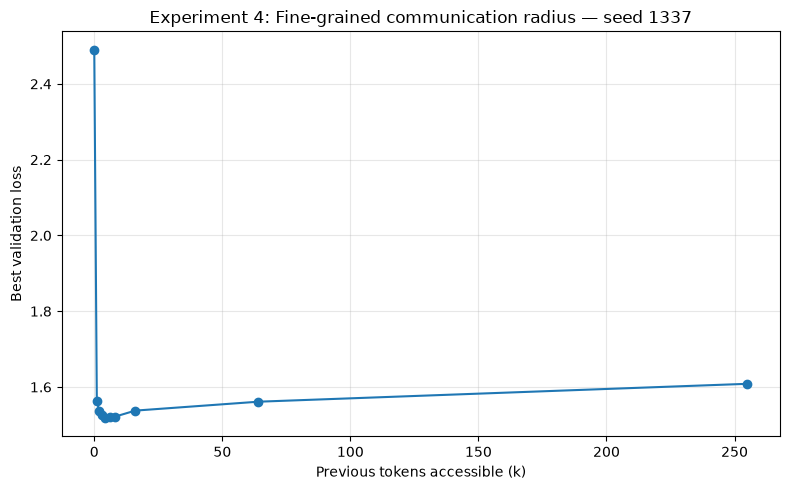

Saved: /workspace/10m_short_window_fine_sweep_experiment4/experiment4_seed1337_short_window_curve.png


In [12]:
REFERENCE_SEED1337 = {
    0: 2.490095181465149,
    1: 1.562058,
    4: 1.518006,
    16: 1.537717,
    64: 1.561206,
    255: 1.60845,
}
rows=[]
for k,loss in REFERENCE_SEED1337.items():
    rows.append({"window_k":k,"best_val_loss":loss,"source":"prior_reference"})
for k in EXP4_WINDOWS:
    rows.append({"window_k":k,"best_val_loss":exp4_results[k]["best_val_loss"],"source":"experiment4"})
exp4_summary=pd.DataFrame(rows).sort_values("window_k").reset_index(drop=True)
display(exp4_summary)
summary_path=OUT_DIR/"experiment4_seed1337_short_window_summary.csv"
exp4_summary.to_csv(summary_path,index=False)
print("Saved:",summary_path)
plt.figure(figsize=(8,5))
plt.plot(exp4_summary["window_k"],exp4_summary["best_val_loss"],marker="o")
plt.xlabel("Previous tokens accessible (k)")
plt.ylabel("Best validation loss")
plt.title("Experiment 4: Fine-grained communication radius — seed 1337")
plt.grid(True,alpha=0.3)
plt.tight_layout()
fig_path=OUT_DIR/"experiment4_seed1337_short_window_curve.png"
plt.savefig(fig_path,dpi=180)
plt.show()
print("Saved:",fig_path)


In [13]:
print("Experiment 4 result files:")
for f in sorted(CKPT_DIR.glob("Window*_seed1337.json")):
    print(" ",f.name)
expected={f"Window{k}_seed1337.json" for k in EXP4_WINDOWS}
found={f.name for f in CKPT_DIR.glob("Window*_seed1337.json")}
missing=expected-found
assert not missing, f"Missing result files: {sorted(missing)}"
print("\nAll Experiment 4A JSON files are present.")


Experiment 4 result files:
  Window2_seed1337.json
  Window3_seed1337.json
  Window6_seed1337.json
  Window8_seed1337.json

All Experiment 4A JSON files are present.


In [14]:
import shutil, zipfile
zip_base="/workspace/experiment4"
zip_file=shutil.make_archive(zip_base,"zip",str(OUT_DIR))
print("Created:",zip_file)
print("Size:",round(os.path.getsize(zip_file)/1024**2,2),"MB")
with zipfile.ZipFile(zip_file,"r") as z:
    print("\nZIP contents:")
    for name in z.namelist(): print(name)


Created: /workspace/experiment4.zip
Size: 0.46 MB

ZIP contents:
data/
results/
experiment4_seed1337_short_window_summary.csv
experiment4_seed1337_short_window_curve.png
results/Window2_seed1337.json
results/Window3_seed1337.json
results/Window6_seed1337.json
results/Window8_seed1337.json
data/input.txt


In [15]:
# ============================================================
# EXPERIMENT 4B — REPLICATION
# Windows: 3, 6, 8
# Seeds: 42, 123
# ============================================================

REPLICATION_WINDOWS = [3, 6, 8]
REPLICATION_SEEDS = [42, 123]

exp4_replication = {}

for seed in REPLICATION_SEEDS:
    exp4_replication[seed] = {}

    for k in REPLICATION_WINDOWS:
        condition = f"Window{k}"

        print("\n" + "=" * 72)
        print(f"FULL RUN: {condition} seed={seed}")
        print("=" * 72)

        # Same residual configuration as all previous
        # window experiments:
        # attention residual ON, FFN residual OFF
        switch = ResidualSwitch(True, False, 1.0, 1.0)

        # Bind k explicitly so each model keeps
        # the intended communication radius.
        class WindowModel(WindowedGPT):
            def __init__(self, switch, _k=k):
                super().__init__(
                    switch=switch,
                    window_size=_k
                )

        result = train_one_run(
            condition=condition,
            seed=seed,
            model_cls=WindowModel,
            switch=switch,
            max_iters=3000,
            eval_interval=100,
            eval_batches=EVAL_BATCHES,
            verbose=True
        )

        # Keep in memory
        exp4_replication[seed][k] = result

        # IMPORTANT: save immediately
        save_result(result)

        print(
            f"\nseed={seed} "
            f"k={k} "
            f"best={result['best_val_loss']:.6f} "
            f"best_step={result['best_step']} "
            f"final={result['final_val_loss']:.6f}"
        )


FULL RUN: Window3 seed=42
Window3          seed=42 step= 100 lr=3.00e-04 train=2.3969 val=2.3937 best=2.3937@100 elapsed=6s
Window3          seed=42 step= 200 lr=2.99e-04 train=2.0017 val=2.0610 best=2.0610@200 elapsed=10s
Window3          seed=42 step= 300 lr=2.97e-04 train=1.7981 val=1.9462 best=1.9462@300 elapsed=15s
Window3          seed=42 step= 400 lr=2.93e-04 train=1.6664 val=1.8459 best=1.8459@400 elapsed=20s
Window3          seed=42 step= 500 lr=2.88e-04 train=1.5894 val=1.7710 best=1.7710@500 elapsed=24s
Window3          seed=42 step= 600 lr=2.81e-04 train=1.5246 val=1.7211 best=1.7211@600 elapsed=29s
Window3          seed=42 step= 700 lr=2.72e-04 train=1.4737 val=1.6841 best=1.6841@700 elapsed=34s
Window3          seed=42 step= 800 lr=2.63e-04 train=1.4424 val=1.6702 best=1.6702@800 elapsed=38s
Window3          seed=42 step= 900 lr=2.52e-04 train=1.4087 val=1.6303 best=1.6303@900 elapsed=43s
Window3          seed=42 step=1000 lr=2.41e-04 train=1.3821 val=1.6135 best=1.6135@

In [16]:
# ============================================================
# EXPERIMENT 4B — THREE-SEED SUMMARY
# ============================================================

import numpy as np
import pandas as pd

# Existing seed-1337 Experiment-4 results
seed1337 = {
    3: 1.527295,
    6: 1.520973,
    8: 1.521617,
}

rows = []

for k in REPLICATION_WINDOWS:

    values = [
        seed1337[k],
        exp4_replication[42][k]["best_val_loss"],
        exp4_replication[123][k]["best_val_loss"],
    ]

    rows.append({
        "window_k": k,
        "seed_1337": values[0],
        "seed_42": values[1],
        "seed_123": values[2],
        "mean": np.mean(values),
        "sample_std": np.std(values, ddof=1),
        "min": np.min(values),
        "max": np.max(values),
    })

exp4_three_seed_summary = pd.DataFrame(rows)

display(exp4_three_seed_summary)

,window_k,seed_1337,seed_42,seed_123,mean,sample_std,min,max
0,3,1.527295,1.527308,1.517451,1.524018,0.005687,1.517451,1.527308
1,6,1.520973,1.525632,1.520637,1.522414,0.002792,1.520637,1.525632
2,8,1.521617,1.539797,1.526760,1.529392,0.009371,1.521617,1.539797


In [17]:
summary_path = OUT_DIR / "experiment4_three_seed_summary.csv"

exp4_three_seed_summary.to_csv(
    summary_path,
    index=False
)

print("Saved:", summary_path)

Saved: /workspace/10m_short_window_fine_sweep_experiment4/experiment4_three_seed_summary.csv


In [18]:
for f in sorted(CKPT_DIR.glob("Window*_seed*.json")):
    print(f.name)

Window2_seed1337.json
Window3_seed123.json
Window3_seed1337.json
Window3_seed42.json
Window6_seed123.json
Window6_seed1337.json
Window6_seed42.json
Window8_seed123.json
Window8_seed1337.json
Window8_seed42.json


In [19]:
# ============================================================
# EXPERIMENT 5: k=1 SELF-ONLY ATTENTION
# ============================================================
#
# Purpose:
#   Test the boundary case of the short-window experiment.
#
#   k=1 means token t can attend ONLY to token t.
#
#   This removes all cross-position communication while keeping
#   the same window-attention implementation used for k=3,6,8.
#
# IMPORTANT:
#   Do not change any other training/model configuration.
# ============================================================

K1_WINDOW = 1
K1_SEEDS = [1337, 42, 123]

print("=" * 72)
print("EXPERIMENT 5: k=1 SELF-ONLY ATTENTION")
print("=" * 72)

print(f"Window size: {K1_WINDOW}")
print(f"Seeds: {K1_SEEDS}")
print("Expected interpretation: self-only / diagonal attention")

EXPERIMENT 5: k=1 SELF-ONLY ATTENTION
Window size: 1
Seeds: [1337, 42, 123]
Expected interpretation: self-only / diagonal attention


In [20]:
# ============================================================
# SANITY CHECK: k=1 MUST BE STRICTLY DIAGONAL
# ============================================================

def check_k1_mask(T=8):
    q = torch.arange(T, device=DEVICE)[:, None]
    k = torch.arange(T, device=DEVICE)[None, :]

    window_k = 1

    allowed = (k <= q) & (k >= q - (window_k - 1))

    print("Allowed attention pattern for k=1:")
    print(allowed.int())

    expected = torch.eye(
        T,
        dtype=torch.bool,
        device=DEVICE
    )

    assert torch.equal(allowed, expected), \
        "ERROR: k=1 is not strictly self-only!"

    print("\nPASS: k=1 allows only t -> t.")
    print("No cross-position communication is possible.")

check_k1_mask()

Allowed attention pattern for k=1:
tensor([[1, 0, 0, 0, 0, 0, 0, 0],
        [0, 1, 0, 0, 0, 0, 0, 0],
        [0, 0, 1, 0, 0, 0, 0, 0],
        [0, 0, 0, 1, 0, 0, 0, 0],
        [0, 0, 0, 0, 1, 0, 0, 0],
        [0, 0, 0, 0, 0, 1, 0, 0],
        [0, 0, 0, 0, 0, 0, 1, 0],
        [0, 0, 0, 0, 0, 0, 0, 1]], device='cuda:0', dtype=torch.int32)

PASS: k=1 allows only t -> t.
No cross-position communication is possible.


In [21]:
# ============================================================
# RUN k=1 — THREE MATCHED SEEDS
# ============================================================

k1_results = []

for seed in K1_SEEDS:

    print("\n" + "=" * 72)
    print(f"FULL RUN: Window1 seed={seed}")
    print("=" * 72)

    set_seed(seed)

    # IMPORTANT:
    # Same residual configuration as the existing window runs:
    # attention residual ON
    # FFN residual OFF
    switch = ResidualSwitch(
        True,   # attention residual
        False,  # FFN residual
        1.0,
        1.0
    )

    model = WindowGPT(
        switch,
        window_k=1
    )

    result = train_one(
        model=model,
        condition="Window1",
        seed=seed
    )

    k1_results.append(result)

    print(
        f"\nseed={seed} "
        f"k=1 "
        f"best={result['best_val_loss']:.6f} "
        f"best_step={result['best_step']} "
        f"final={result['final_val_loss']:.6f}"
    )


FULL RUN: Window1 seed=1337


NameError: name 'WindowGPT' is not defined

In [22]:
# ============================================================
# EXPERIMENT 4 FOLLOW-UP
# k = 1 (self-only attention)
# Missing matched seeds: 42 and 123
# ============================================================

K = 1
SEEDS = [42, 123]

# Same residual configuration used by Experiment 4
WINDOW_ONLY = ResidualSwitch(
    True,   # attention residual ON
    False,  # FFN residual OFF
    1.0,
    1.0
)

k1_results = {}

for seed in SEEDS:

    condition = "Window1"

    print("\n" + "=" * 72)
    print(f"FULL RUN: {condition} seed={seed}")
    print("=" * 72)

    # Exact same pattern used by Experiment 4
    class WindowModel(WindowedGPT):
        def __init__(self, switch, _k=K):
            super().__init__(
                switch=switch,
                window_size=_k
            )

    result = train_one_run(
        condition=condition,
        seed=seed,
        model_cls=WindowModel,
        switch=WINDOW_ONLY,
        max_iters=3000,
        eval_interval=100,
        eval_batches=EVAL_BATCHES,
        verbose=True
    )

    k1_results[seed] = result

    # Save immediately
    save_result(result)

    print(
        f"\nseed={seed} "
        f"k={K} "
        f"best={result['best_val_loss']:.6f} "
        f"best_step={result['best_step']} "
        f"final={result['final_val_loss']:.6f}"
    )


FULL RUN: Window1 seed=42
Window1          seed=42 step= 100 lr=3.00e-04 train=2.2650 val=2.2672 best=2.2672@100 elapsed=6s
Window1          seed=42 step= 200 lr=2.99e-04 train=1.9040 val=1.9833 best=1.9833@200 elapsed=10s
Window1          seed=42 step= 300 lr=2.97e-04 train=1.7317 val=1.8898 best=1.8898@300 elapsed=15s
Window1          seed=42 step= 400 lr=2.93e-04 train=1.6314 val=1.8087 best=1.8087@400 elapsed=20s
Window1          seed=42 step= 500 lr=2.88e-04 train=1.5726 val=1.7755 best=1.7755@500 elapsed=24s
Window1          seed=42 step= 600 lr=2.81e-04 train=1.5273 val=1.7345 best=1.7345@600 elapsed=29s
Window1          seed=42 step= 700 lr=2.72e-04 train=1.4912 val=1.7190 best=1.7190@700 elapsed=34s
Window1          seed=42 step= 800 lr=2.63e-04 train=1.4674 val=1.6910 best=1.6910@800 elapsed=38s
Window1          seed=42 step= 900 lr=2.52e-04 train=1.4388 val=1.6657 best=1.6657@900 elapsed=43s
Window1          seed=42 step=1000 lr=2.41e-04 train=1.4232 val=1.6496 best=1.6496@